In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from least_core import exact_least_core


# Utility wrapper for least core

class _FeatureDataWrapper:
    """Wrapper so least_core.exact_least_core can query feature names."""
    def __init__(self, feature_names):
        self.data_names = list(feature_names)

    def __len__(self):
        return len(self.data_names)


class FeatureUtility:
    """
    Cooperative game:
        - Players = features
        - Coalition S = subset of features
        - v(S) = average predicted probability of TRUE class
                when only features in S are used.
    """
    def __init__(self, model, X_train, X_test, y_test, feature_names):
        self.model = model
        self.X_train = X_train.reset_index(drop=True)
        self.X_test = X_test.reset_index(drop=True)
        self.y_test = np.array(y_test, dtype=int)
        self.feature_names = list(feature_names)
        self.data = _FeatureDataWrapper(self.feature_names)

        # Baseline value for missing features
        self.baseline = self.X_train.mean(axis=0).values

    def __call__(self, coalition):
        coalition = list(coalition)

        if not coalition:
            return 0.0  # empty coalition = no predictive power

        # Create masked dataset
        X_masked = np.tile(self.baseline, (self.X_test.shape[0], 1))
        X_masked[:, coalition] = self.X_test.iloc[:, coalition].values

        # Predict and extract probability of the true class
        probs = self.model.predict_proba(X_masked)
        true_probs = probs[np.arange(len(self.y_test)), self.y_test]

        return float(true_probs.mean())


# Least-Core attribution

def compute_least_core_attribution(model, X_train, X_test, y_test, feature_names, solver=None):
    """
    Returns: pd.Series of least-core attributions.
    """
    utility = FeatureUtility(model, X_train, X_test, y_test, feature_names)

    options = {}
    if solver:
        options["solver"] = solver  # e.g. "ECOS", "SCS"

    result = exact_least_core(utility, options=options)
    return pd.Series(result.values, index=feature_names, name="LeastCore")


# Example Usage

if __name__ == "__main__":
    # Load dataset
    data = np.load("soil_spi_preprocessed.npz", allow_pickle=True)

    X_train = pd.DataFrame(data["X_train"], columns=data["feature_names"])
    X_test  = pd.DataFrame(data["X_test"],  columns=data["feature_names"])
    y_train = data["y_train"]
    y_test  = data["y_test"]
    feature_names = list(data["feature_names"])

    # Train classifier
    from sklearn.ensemble import RandomForestClassifier
    model = RandomForestClassifier(n_estimators=200, random_state=42)
    model.fit(X_train, y_train)

    # Compute least-core attributions
    leastcore_values = compute_least_core_attribution(
        model,
        X_train,
        X_test,
        y_test,
        feature_names,
        solver=None
    )

    print("\n===== Least-Core Attributions =====")
    print(leastcore_values)


===== Least-Core Attributions =====
Organic Carbon             0.071526
Nitrogen                   0.222046
Phosphorus                 0.052436
Potassium                  0.186096
pH                         0.164201
Zinc                       0.050051
Electrical Conductivity    0.077431
Name: LeastCore, dtype: float64


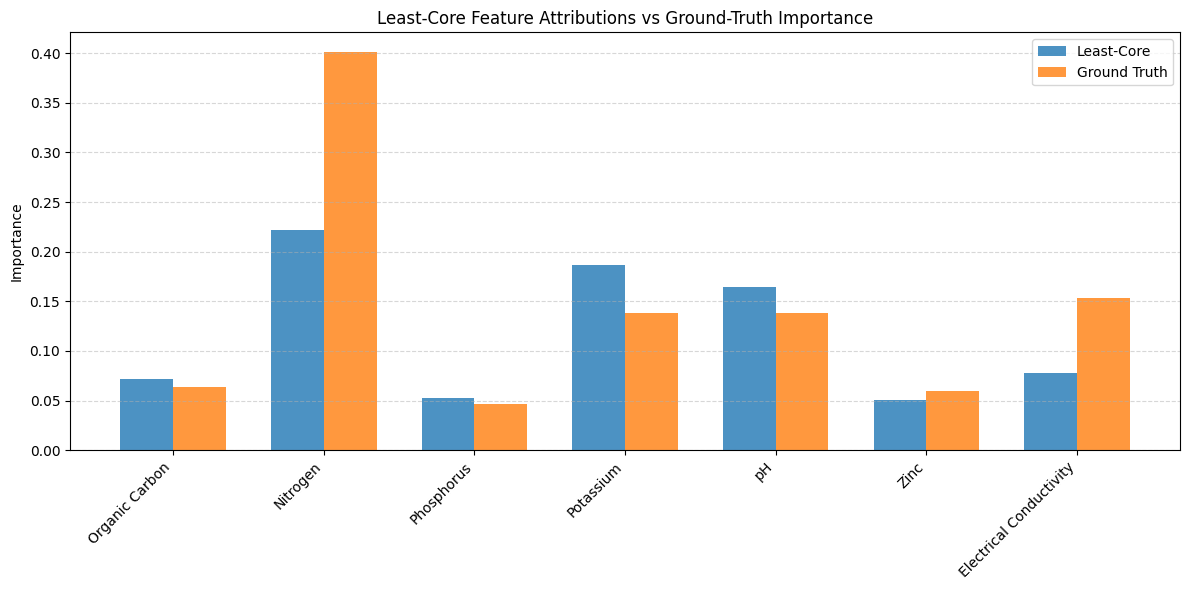

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Least-Core values
least_core = {
    "Organic Carbon": 0.071526,
    "Nitrogen": 0.222046,
    "Phosphorus": 0.052436,
    "Potassium": 0.186096,
    "pH": 0.164201,
    "Zinc": 0.050051,
    "Electrical Conductivity": 0.077431
}

# Ground Truth values
ground_truth = {
    "Nitrogen": 0.401,
    "Electrical Conductivity": 0.153,
    "Potassium": 0.138,
    "pH": 0.138,
    "Organic Carbon": 0.064,
    "Zinc": 0.060,
    "Phosphorus": 0.047
}

# Convert to DataFrame
df = pd.DataFrame({
    "Least-Core": least_core,
    "Ground Truth": ground_truth
})

df = df.T  # transpose
df = df.reindex(["Least-Core", "Ground Truth"])  # row order

# Plot
plt.figure(figsize=(12, 6))

x = np.arange(len(df.columns))
width = 0.35

plt.bar(x - width/2, df.loc["Least-Core"], width, label="Least-Core", alpha=0.8)
plt.bar(x + width/2, df.loc["Ground Truth"], width, label="Ground Truth", alpha=0.8)

plt.xticks(x, df.columns, rotation=45, ha='right')
plt.ylabel("Importance")
plt.title("Least-Core Feature Attributions vs Ground-Truth Importance")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [4]:
import warnings
import os
import sys
warnings.filterwarnings("ignore")

repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

import numpy as np
import pandas as pd
from cgt_xai.concepts.gately_point import exact_gately_value


# Utility wrapper for Gately

class _FeatureDataWrapper:
    def __init__(self, feature_names):
        self.data_names = list(feature_names)

    def __len__(self):
        return len(self.data_names)


class FeatureUtility:
    """
    v(S) = average predicted probability of TRUE class
           when only features in S are used.
    """
    def __init__(self, model, X_train, X_test, y_test, feature_names):
        self.model = model
        self.X_train = X_train.reset_index(drop=True)
        self.X_test = X_test.reset_index(drop=True)
        self.y_test = np.array(y_test, dtype=int)
        self.feature_names = list(feature_names)
        self.data = _FeatureDataWrapper(self.feature_names)

        self.baseline = self.X_train.mean(axis=0).values

    def __call__(self, coalition):
        coalition = list(coalition)

        if not coalition:
            return 0.0

        X_masked = np.tile(self.baseline, (self.X_test.shape[0], 1))
        X_masked[:, coalition] = self.X_test.iloc[:, coalition].values

        probs = self.model.predict_proba(X_masked)
        true_probs = probs[np.arange(len(self.y_test)), self.y_test]

        return float(true_probs.mean())


# Gately attribution

def compute_gately_attribution(model, X_train, X_test, y_test, feature_names):
    utility = FeatureUtility(model, X_train, X_test, y_test, feature_names)

    result = exact_gately_value(utility)

    return pd.Series(result.values, index=feature_names, name="Gately")


# Example Usage

if __name__ == "__main__":

    data = np.load("../../datasets/soil_spi_preprocessed.npz", allow_pickle=True)

    X_train = pd.DataFrame(data["X_train"], columns=data["feature_names"])
    X_test  = pd.DataFrame(data["X_test"],  columns=data["feature_names"])
    y_train = data["y_train"]
    y_test  = data["y_test"]
    feature_names = list(data["feature_names"])

    from sklearn.ensemble import RandomForestClassifier

    model = RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
    model.fit(X_train, y_train)

    gately_values = compute_gately_attribution(
        model,
        X_train,
        X_test,
        y_test,
        feature_names
    )

    print("\n===== Gately Attributions =====")
    print(gately_values)


===== Gately Attributions =====
Organic Carbon             0.092630
Nitrogen                   0.197480
Phosphorus                 0.056334
Potassium                  0.186632
pH                         0.173507
Zinc                       0.048818
Electrical Conductivity    0.068470
Name: Gately, dtype: float64
